In [1]:
import pandas as pd

In [7]:
from google.colab import files
uploaded = files.upload()

Saving 2) Stock Prices Data Set (1).csv to 2) Stock Prices Data Set (1).csv


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("2) Stock Prices Data Set (1).csv")

df.columns = df.columns.str.strip().str.lower()
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.dropna(subset=["open", "close"])

X = df[["open"]]
y = df["close"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("R-squared:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

Coefficient: 0.9998744981397097
Intercept: 0.026677540332201488
R-squared: 0.9997383343436389
Mean Squared Error: 2.7260823685319737


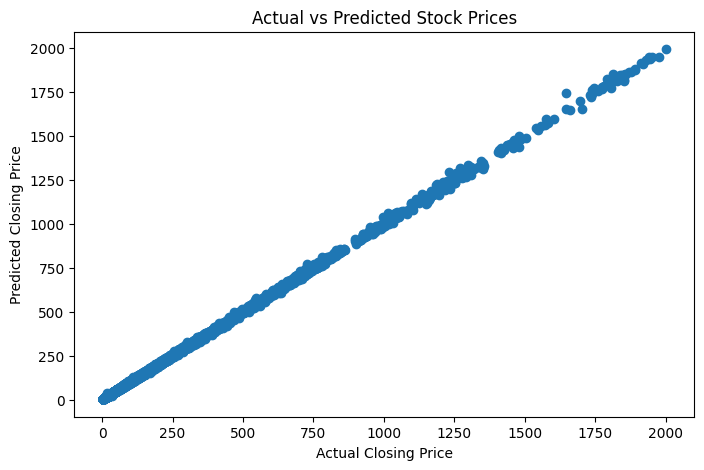

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Closing Price")
plt.ylabel("Predicted Closing Price")
plt.title("Actual vs Predicted Stock Prices")
plt.show()